# ANÁLISIS DE ACTIVOS FINANCIEROS

### 📊 Activos financieros como variables aleatorias  

En este curso vamos a considerar un **activo financiero** como una **variable aleatoria** que sigue una distribución de probabilidad (PDF).  
Los **precios** en sí no nos resultan útiles para el análisis, por lo que utilizaremos los **retornos**, que reflejan mejor los cambios relativos y las propiedades estadísticas del activo.  


### 📈 ¿Por qué usamos retornos y no precios?  

En finanzas trabajamos con **retornos** en lugar de precios porque:  
- Permiten comparar activos con diferentes niveles de precio.  
- Son aditivos en el tiempo y más adecuados para el análisis estadístico.  
- Capturan mejor la variabilidad relativa de los activos.  

Además, utilizamos **retornos logarítmicos** porque:  
- Facilitan la agregación temporal (el retorno total es la suma de los retornos logarítmicos).  
- Sus propiedades estadísticas se aproximan mejor a una **distribución normal**, lo que simplifica el modelado y la inferencia.  


In [2]:
!pip install mplfinance

In [3]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt
import mplfinance as mpf
import plotly.graph_objects as go
import warnings

import yfinance as yf

import statsmodels.api as sm

# print(plt.style.available) #list of available styles
plt.style.use("ggplot")

warnings.simplefilter(action="ignore", category=FutureWarning)

Primero, descargamos los datos OHLC del Santander para visualizarlos con diferentes herramientas.

In [6]:
data_df= yf.download(
    "SAN.MC",
    start="2015-01-01",
    end="2025-09-10",
    auto_adjust=True,
    multi_level_index=True,
    actions=True
)
data_df

[*********************100%***********************]  1 of 1 completed


Price,Close,Dividends,High,Low,Open,Stock Splits,Volume
Ticker,SAN.MC,SAN.MC,SAN.MC,SAN.MC,SAN.MC,SAN.MC,SAN.MC
Date,,,,,,,
2015-01-02,4.227657,0.0,4.278767,4.172940,4.260126,0.0,83205286
2015-01-05,4.034645,0.0,4.254716,4.025625,4.199397,0.0,113251404
2015-01-06,3.964293,0.0,4.071924,3.962489,4.052683,0.0,90444216
2015-01-07,3.989547,0.0,4.074930,3.949861,3.998566,0.0,80771172
2015-01-08,4.122431,0.0,4.135659,4.039453,4.076733,0.0,26289975
...,...,...,...,...,...,...,...
2025-09-03,7.791096,0.0,7.794951,7.700502,7.758328,0.0,14317072
2025-09-04,7.889400,0.0,7.889400,7.725560,7.806517,0.0,20100628


In [7]:
data_df = yf.download(
    "SAN.MC",
    start="2015-01-01",
    end="2025-09-10",
    auto_adjust=False,
    multi_level_index=False,
    actions=True
)

data_df

[*********************100%***********************]  1 of 1 completed


,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2015-01-02,4.227657,6.627242,0.0,6.707361,6.541468,6.678141,0.0,83205286
2015-01-05,4.034645,6.324676,0.0,6.669658,6.310537,6.582941,0.0,113251404
2015-01-06,3.964293,6.214394,0.0,6.383115,6.211567,6.352953,0.0,90444216
2015-01-07,3.989547,6.253982,0.0,6.387828,6.191772,6.268121,0.0,80771172
2015-01-08,4.122431,6.462291,0.0,6.483028,6.332216,6.390656,0.0,26289975
...,...,...,...,...,...,...,...,...
2025-09-03,7.791096,8.084000,0.0,8.088000,7.990000,8.050000,0.0,14317072
2025-09-04,7.889400,8.186000,0.0,8.186000,8.016000,8.100000,0.0,20100628
2025-09-05,7.795915,8.089000,0.0,8.248000,8.054000,8.200000,0.0,18758770


In [8]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2735 entries, 2015-01-02 to 2025-09-09
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Adj Close     2735 non-null   float64
 1   Close         2735 non-null   float64
 2   Dividends     2735 non-null   float64
 3   High          2735 non-null   float64
 4   Low           2735 non-null   float64
 5   Open          2735 non-null   float64
 6   Stock Splits  2735 non-null   float64
 7   Volume        2735 non-null   int64  
dtypes: float64(7), int64(1)
memory usage: 192.3 KB


In [9]:
data_df.describe()

,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
count,2735.000000,2735.000000,2735.000000,2735.000000,2735.000000,2735.000000,2735.000000,2.735000e+03
mean,3.272561,4.080912,0.000667,4.130622,4.029784,4.081719,0.000382,6.849096e+07
std,1.104595,1.281871,0.007167,1.287672,1.270659,1.278983,0.019953,6.360819e+07
min,1.204597,1.473533,0.000000,1.502475,1.439417,1.444017,0.000000,0.000000e+00
25%,2.594954,3.197000,0.000000,3.236750,3.150000,3.197500,0.000000,3.405268e+07
50%,3.100525,3.863042,0.000000,3.908857,3.820000,3.868792,0.000000,5.084634e+07
75%,3.924130,4.872639,0.000000,4.918649,4.811372,4.882250,0.000000,7.871665e+07
max,8.021436,8.323000,0.142329,8.338000,8.254000,8.290000,1.043478,9.487686e+08


In [10]:
fig = go.Figure(
    data=[
        go.Candlestick(
            x=data_df.loc["2018-06":"2018-08"].index,
            open=data_df.loc["2018-06":"2018-08"]["Open"],
            high=data_df.loc["2018-06":"2018-08"]["High"],
            low=data_df.loc["2018-06":"2018-08"]["Low"],
            close=data_df.loc["2018-06":"2018-08"]["Close"],
        )
    ]
)

fig.update_layout(title=f"Santander Candlestick Price Chart", xaxis_tickfont_size=14)
fig.update_layout(xaxis_rangeslider_visible=False)
fig.show()

En el ámbito financiero, no suele ser común trabajar directamente con los precios de los activos, sino que trabajamos con los **retornos** de los precios.

**Retornos logarítmicos:**

$$r_t = ln(\frac{P_t}{P_{t-1}}) = ln(P_t) - ln(P_{t-1})$$

donde, como antes, $P_t$ y $P_{t-1}$ representan los precios de cierre en los instantes de tiempo $t$ y $t-1$, respectivamente.

Se utilizan siempre **retornos logarítmicos**:
* Los logaritmos de los precios siguen una distribución normal, esto es, los precios siguen una distribución log-normal.
* Cuando la variación en precio es pequeña, los retornos logarítmicos son muy similares a los retornos aritméticos.
* $log(\frac{p_d}{p_{d-1}})=log(p_d)-log(p_{d-1})$
* La suma (resta) es numéricamente más estable que la multiplicación (división) cuando los números son muy pequeños.


Se trabaja siempre con los precios ajustados

In [11]:
data_df["ret"] = np.log(data_df.loc[:, ["Adj Close"]]).diff()

In [12]:
data_df.columns

Index(['Adj Close', 'Close', 'Dividends', 'High', 'Low', 'Open',
       'Stock Splits', 'Volume', 'ret'],
      dtype='object')

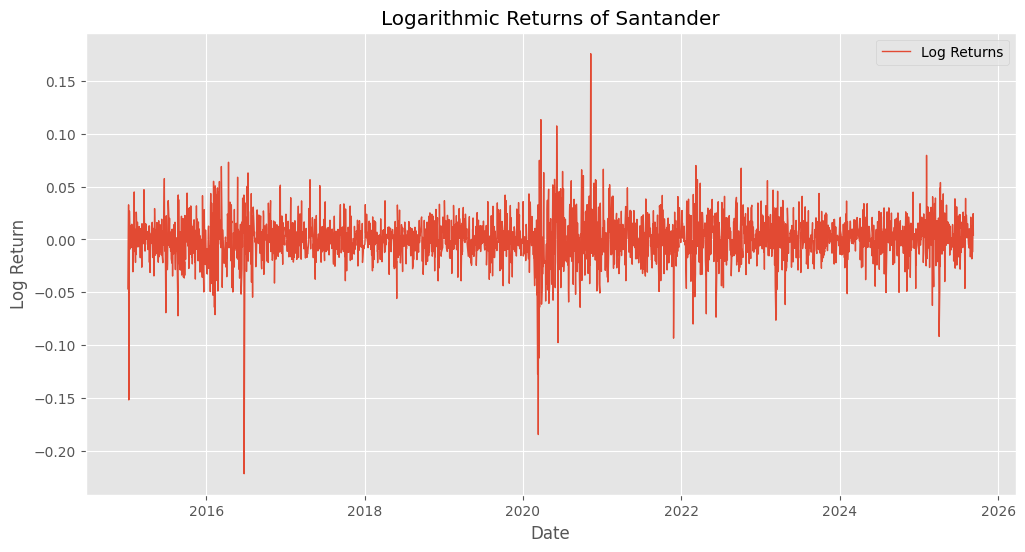

In [13]:
# Crear figura
plt.figure(figsize=(12,6))
plt.plot(data_df["ret"].index, data_df["ret"].values, label="Log Returns", linewidth=1)

# Personalización
plt.title("Logarithmic Returns of Santander")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.legend()
plt.grid(True)

plt.show()

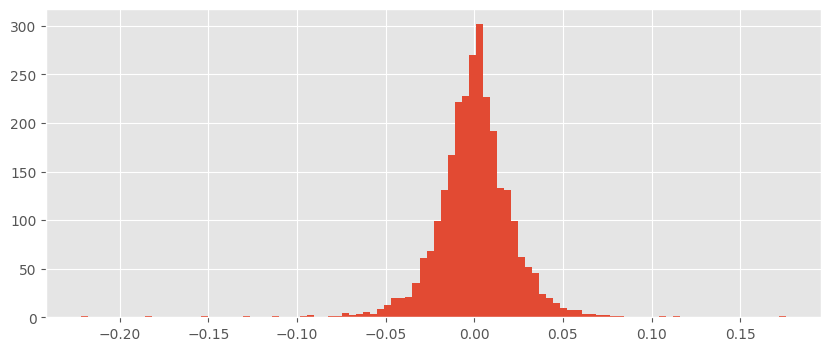

In [14]:
plt.figure(figsize=(10, 4))
plt.hist(data_df["ret"], bins=100)
plt.show()

Viendo la figura, aparentemente sigue una distribución Normal (Gaussiana). Entonces, podemos caracterizar los datos mediante su media y su desviación estándar:

1. Se calcula la rentabilidad media de los retornos:

$$\bar{r} = \frac{1}{n} \sum_{i=1}^n r_i$$

2. Se calcula la varianza de los retornos:

$$\sigma^2 = \frac{1}{n-1} \sum_{i=1}^{n} (r_i - \bar{r})^2$$

3. Se calcula la desviación típica de los retornos:

$$\sigma = \sqrt{\frac{1}{n-1} \sum_{i=1}^{n} (r_i - \bar{r})^2}$$

La rentabilidad, varianza y desviación típica **siempre se expresan en términos anuales**:

- Si los datos son **diarios**, consideramos que hay **252 días al año** de negociación.
- Si los datos son **mensuales**, consideramos que hay **12 meses al año**.

In [ ]:
retorno = data_df["ret"].mean() * 252
volatilidad = data_df["ret"].std() * np.sqrt(252)

In [ ]:
print(f" Rentabilidad media: {retorno:.4f} \n")
print(f" Desviación estándar: {volatilidad:.4f} \n")

 Rentabilidad media: 0.0590 

 Desviación estándar: 0.3421 



Dado que los inversores tienen aversión al riesgo, los activos los representamos por el **binomio rentabilidad-riesgo**:

- La **rentabilidad** se mide como la media de los retornos.
    
- El **riesgo** se mide a través de la volatilidad, que es la desviación estándar de los rendimientos.

## EJERCICIO: BÁJATE LOS DATOS DE APPLE DE LOS AÑOS 2015 al 2024 INCLUIDOS:

##          CALCULA Y GRAFICA LOS RETORNOS DIARIOS

##          CALCULA E IMPRIME LA RENTABILIDAD Y VOLATILIDAD ANUAL

In [ ]:
aapl_ret = np.log(aapl_df).diff()

## COMPAREMOS DISTINTOS ACTIVOS

Vamos a descargar dos grupos de activos que nos servirán para analizar distintos comportamientos.

In [16]:
file_path = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Feb-2025/Tema_1_Activos_Intro/data/data_OHLC.xlsx"
data_OHLC_df = pd.read_excel(file_path, header=[0, 1], index_col=0, parse_dates=True)

file_path = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Feb-2025/Tema_1_Activos_Intro/data/data_OHLC_corr.xlsx"
data_OHLC_df_corr = pd.read_excel(
    file_path, header=[0, 1], index_col=0, parse_dates=True
)

In [17]:
data_OHLC_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3550 entries, 2013-10-07 to 2023-10-05
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   (Adj Close, AAPL)     2516 non-null   float64
 1   (Adj Close, BTC-USD)  3306 non-null   float64
 2   (Adj Close, ELE.MC)   2559 non-null   float64
 3   (Adj Close, IAU)      2516 non-null   float64
 4   (Adj Close, IEF)      2516 non-null   float64
 5   (Adj Close, TSLA)     2516 non-null   float64
 6   (Close, AAPL)         2516 non-null   float64
 7   (Close, BTC-USD)      3306 non-null   float64
 8   (Close, ELE.MC)       2559 non-null   float64
 9   (Close, IAU)          2516 non-null   float64
 10  (Close, IEF)          2516 non-null   float64
 11  (Close, TSLA)         2516 non-null   float64
 12  (High, AAPL)          2516 non-null   float64
 13  (High, BTC-USD)       3306 non-null   float64
 14  (High, ELE.MC)        2559 non-null   float64
 15  (Hi

In [18]:
data_close_df = data_OHLC_df["Adj Close"]


<Axes: >

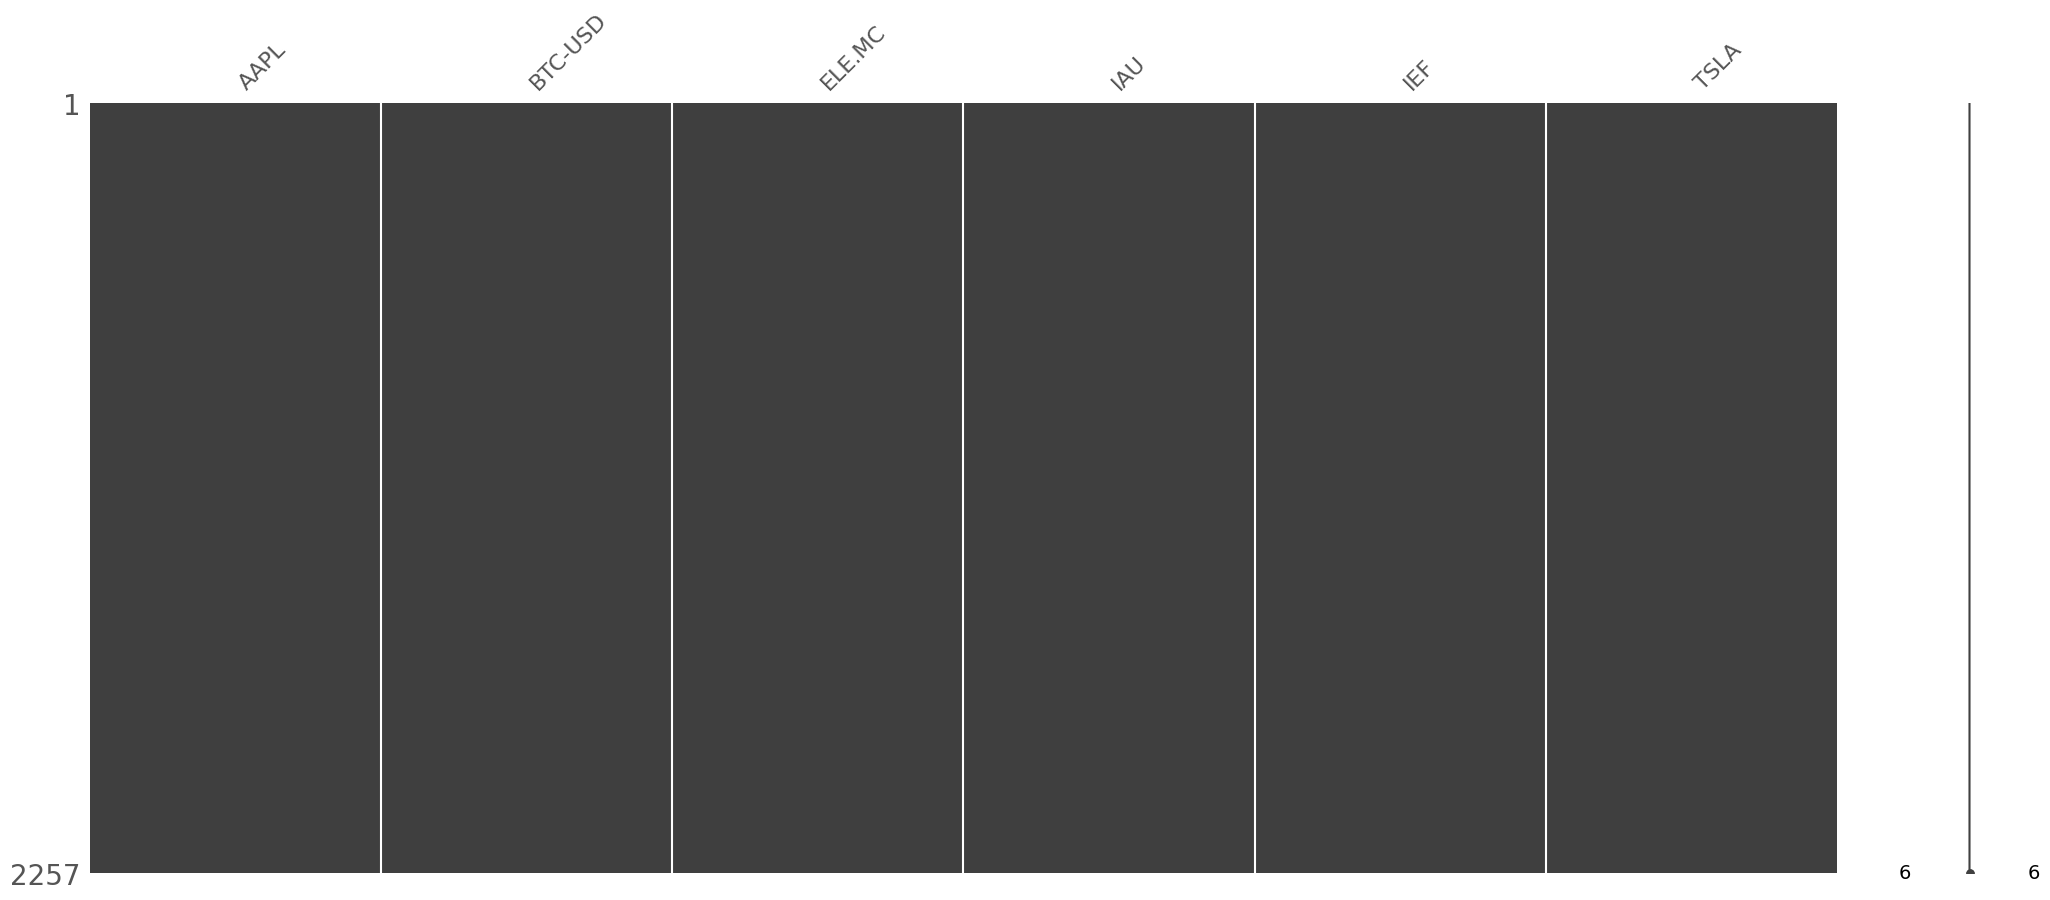

In [20]:
import missingno as msno

msno.matrix(data_close_df)

Eliminamos todos los NaN de las filas, dejando solamente aquellas donde tenemos todos los datos disponibles.

<Axes: >

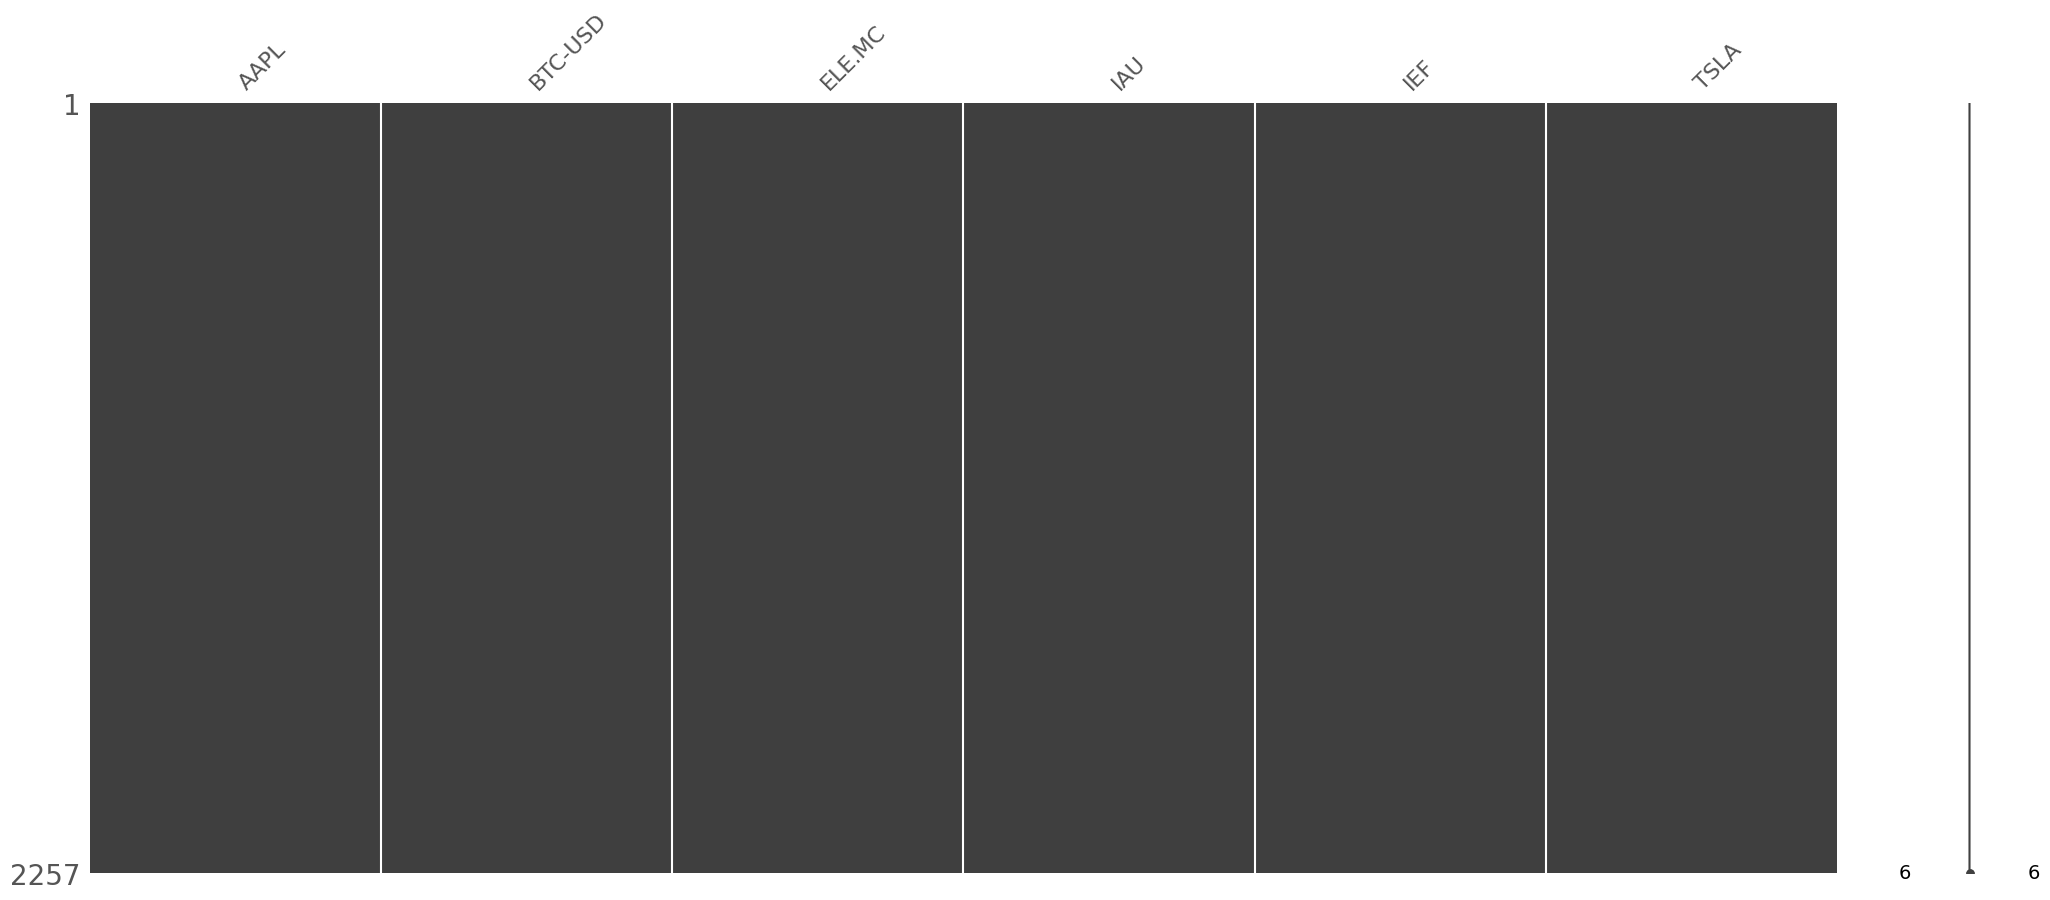

In [21]:
data_close_df = data_close_df.dropna(axis=0, how="any")
msno.matrix(data_close_df)

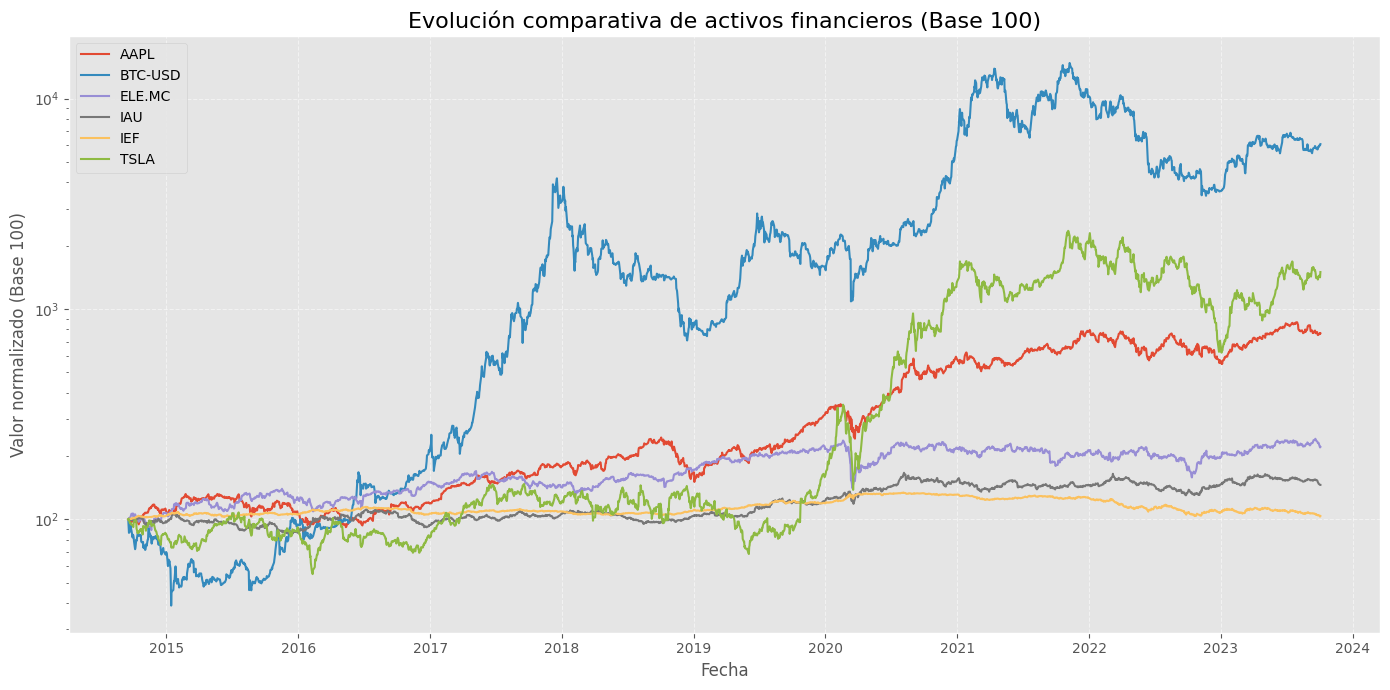

In [27]:
# Normalizar los precios a base 100
precios_base_100 = (data_close_df / data_close_df.iloc[0]) * 100

# Crear el gráfico de evolución temporal
plt.figure(figsize=(14, 7))
for columna in precios_base_100.columns:
    plt.plot(precios_base_100.index, precios_base_100[columna], label=columna, linewidth=1.5)

plt.title("Evolución comparativa de activos financieros (Base 100)", fontsize=16)
plt.xlabel("Fecha", fontsize=12)
plt.ylabel("Valor normalizado (Base 100)", fontsize=12)
plt.yscale("log")  # Escala logarítmica recomendada debido a la gran diferencia entre BTC-USD y el resto
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [22]:
ret_close_df = np.log(data_close_df).diff().dropna()

Hacemos unas gráficas para ver la rentabilidad y volatilidad de cada activo.

In [23]:
# Puedes calcular los valores medios y la desviación estándar de cada columna así:
means = ret_close_df.mean()
stds = ret_close_df.std()

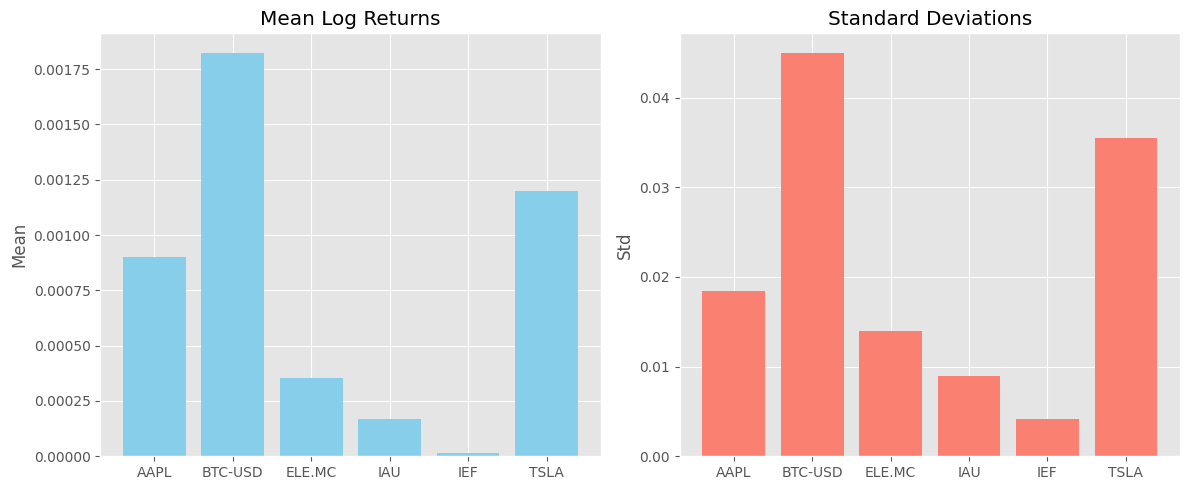

In [24]:
# Crear figura con dos gráficos en una línea
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Gráfico de medias
axes[0].bar(means.index, means, color="skyblue")
axes[0].set_title("Mean Log Returns")
axes[0].set_ylabel("Mean")

# Gráfico de desviaciones estándar
axes[1].bar(means.index, stds, color="salmon")
axes[1].set_title("Standard Deviations")
axes[1].set_ylabel("Std")

plt.tight_layout()
plt.show()

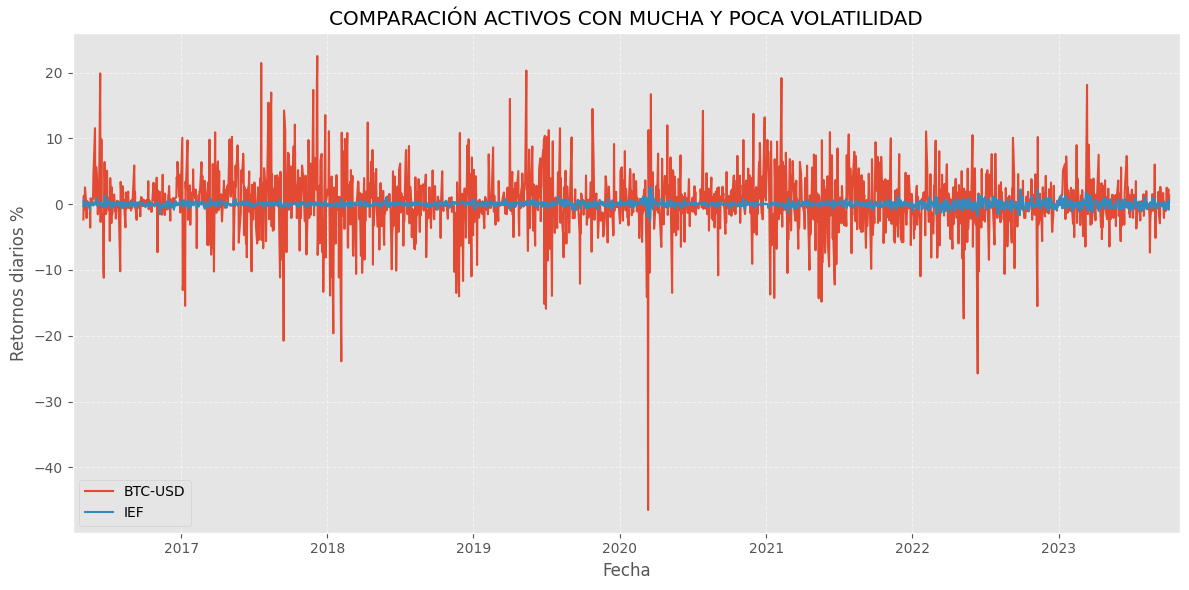

In [25]:
 #Subconjunto desde 2016-05-01 y columnas de interés
subset = ret_close_df.loc["2016-05-01":, ["BTC-USD", "IEF"]].dropna()

plt.figure(figsize=(12, 6))
plt.plot(subset.index, subset["BTC-USD"] * 100, label="BTC-USD")  # a %
plt.plot(subset.index, subset["IEF"] * 100, label="IEF")          # a %

plt.title("COMPARACIÓN ACTIVOS CON MUCHA Y POCA VOLATILIDAD")
plt.xlabel("Fecha")
plt.ylabel("Retornos diarios %")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.margins(x=0.01)
plt.tight_layout()
plt.show()

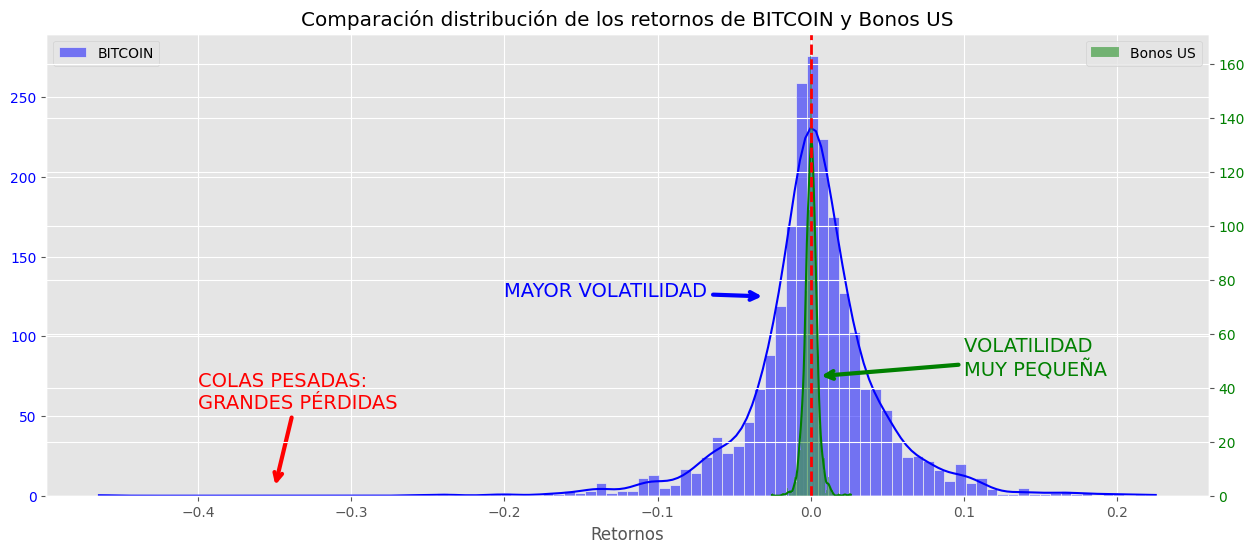

In [26]:
fig, ax1 = plt.subplots(figsize=(15, 6))

# Crear el primer gráfico con sns.histplot
sns.histplot(
    data=ret_close_df,
    x="BTC-USD",
    ax=ax1,
    bins=100,
    color="blue",
    kde=True,
    alpha=0.5,
    label="BITCOIN",
)
ax1.set_xlabel("Retornos")
ax1.set_ylabel("", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")
ax1.legend(loc="upper left")

# # Añadir texto en ax2
# text_x = -0.4
# text_y = 25

# ax1.text(-0.2, 125, f"MAYOR VOLATILIDAD", fontsize=12, color='blue')

ax1.annotate(
    "MAYOR VOLATILIDAD",
    xy=(-0.03, 125),
    xytext=(-0.2, 125),
    arrowprops=dict(arrowstyle="->", linewidth=3, color="blue"),
    fontsize=14,
    color="blue",
)

ax1.annotate(
    "VOLATILIDAD \nMUY PEQUEÑA",
    xy=(0.005, 75),
    xytext=(0.1, 75),
    arrowprops=dict(arrowstyle="->", linewidth=3, color="green"),
    fontsize=14,
    color="green",
)

ax1.annotate(
    "COLAS PESADAS: \nGRANDES PÉRDIDAS",
    xy=(-0.35, 5),
    xytext=(-0.4, 55),
    arrowprops=dict(arrowstyle="->", linewidth=3, color="red"),
    fontsize=14,
    color="RED",
)


# Duplicar el eje Y para el segundo gráfico
ax2 = ax1.twinx()

# Crear el segundo gráfico con sns.histplot
sns.histplot(
    data=ret_close_df,
    x="IEF",
    ax=ax2,
    bins=100,
    color="green",
    kde=True,
    alpha=0.5,
    label="Bonos US",
)
ax2.set_ylabel("", color="green")
ax2.tick_params(axis="y", labelcolor="green")
ax2.legend(loc="upper right")

# Añadir una línea vertical en el eje X en 0
plt.axvline(x=0, color="red", linestyle="--", linewidth=2)
# Configurar título y mostrar el gráfico
plt.title("Comparación distribución de los retornos de BITCOIN y Bonos US")
plt.show()

Hemos podido comprobar que los retornos **no siempre siguen una distribución normal**. Concretamente, hemos visto que las colas de la distribución de los retornos son más pesadas que las de una distribución normal. Esto quiere decir que hay más probabilidad de que ocurran eventos extremos (tanto positivos como negativos) de lo que cabría esperar si los retornos siguieran una distribución normal.

Necesitamos más estadísticos para describir un activo. Por tanto vamos a estimar la asimetría y la curtosis de la función de distribución de los retornos.

## 1.4 Asimetría y Curtosis

### Asimetría

El tercer momento de una función de distribución nos mide su nivel de asimetría. Así:

* Una asimetría positiva indica que la acción tiene una mayor probabilidad por encima de la media.

* Una asimetría negativa indica que la acción tiene una mayor probabilidad por debajo de la media.

* Una asimetría neutra indica que la acción tiene una probabilidad equilibrada a ambos lados de la media.

Analicemos la asimetría de los retornos de los activos que tenemos. Si los retornos siguieran una distribución normal, la asimetría debería ser 0.

In [ ]:
df_skew = ret_close_df.skew()


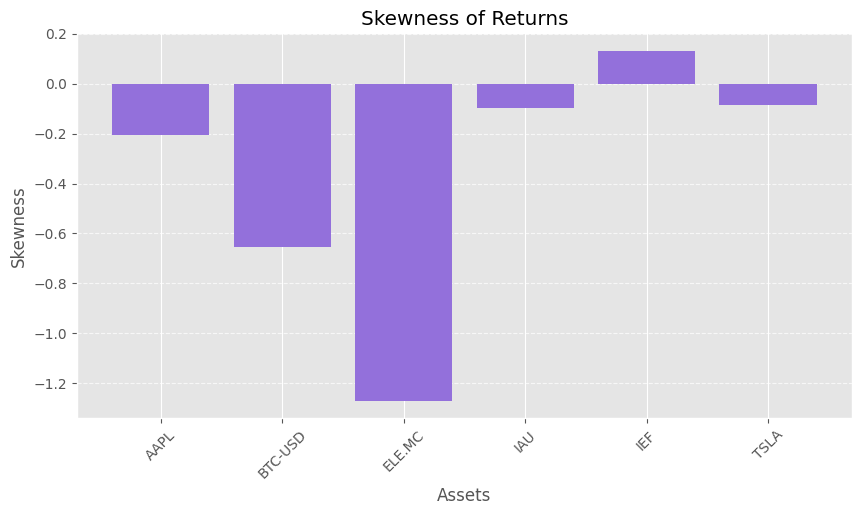

In [ ]:
plt.figure(figsize=(10,5))
plt.bar(df_skew.index, df_skew, color="mediumpurple")

plt.title("Skewness of Returns")
plt.xlabel("Assets")
plt.ylabel("Skewness")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

Podemos observar que, mayoritariamente, predominan los activos con asimetrías negativas. Eso significa que, por lo general, la cola izquierda es más pesada que la derecha. Es decir, hay más probabilidad de que ocurran eventos negativos extremos que positivos extremos.

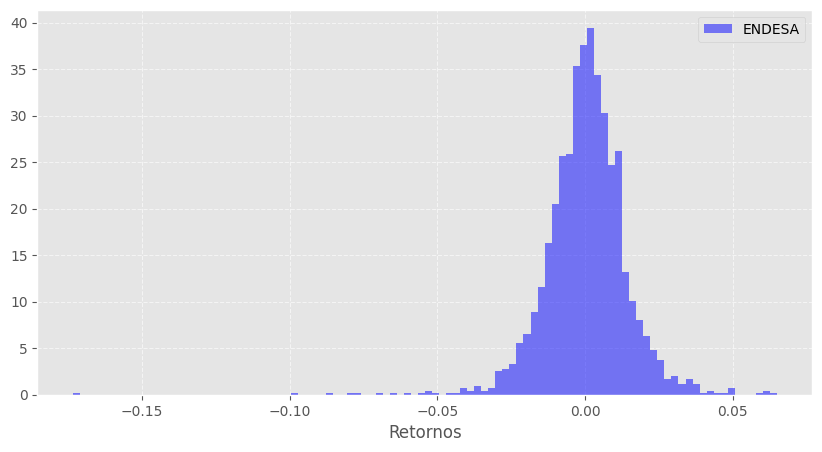

In [ ]:

# Histograma con matplotlib
plt.figure(figsize=(10,5))
plt.hist(
    ret_close_df["ELE.MC"],
    bins=100,
    color="blue",
    alpha=0.5,
    label="ENDESA",
    density=True  # equivalente a seaborn kde=True, aunque sin curva
)
# Personalización
plt.xlabel("Retornos")
plt.ylabel("")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [ ]:
print("Asimetría de Endesa:", np.around(ret_close_df["ELE.MC"].skew(), decimals=3))

Asimetría de Endesa: -1.27


HACER EL GRÁFICO PARA ORACLE

<hr>

### Curtosis

La curtosis, en estadística, es una medida que describe la forma de la distribución de los datos, específicamente cuán "pesadas" o "ligeras" son las colas de la distribución en comparación con una distribución normal (campana de Gauss). Aquí te ofrezco una forma intuitiva de explicarla:

Imagina que tienes dos montañas hechas de arena. La primera montaña es amplia y baja, extendiéndose suavemente hacia los lados. La segunda montaña es más alta y puntiaguda, con lados más empinados. Ambas montañas pueden tener la misma cantidad de arena, pero están distribuidas de manera diferente.

- **Curtosis baja (Platicúrtica)**: Es como la primera montaña, más plana y extendida. Esto significa que los datos están más dispersos, hay menos concentración de datos cerca del promedio y las colas son más "ligeras". En esta distribución, los eventos extremos (muy lejos del promedio) son menos comunes.

- **Curtosis alta (Leptocúrtica)**: Es como la segunda montaña, más alta y estrecha. Aquí, los datos están más concentrados cerca del promedio y las colas son más "pesadas". Esto implica que hay una mayor probabilidad de encontrar valores extremos.

- **Curtosis normal (Mesocúrtica)**: Es similar a la distribución normal, ni muy plana ni muy puntiaguda. Representa un equilibrio entre la dispersión de los datos y la frecuencia de eventos extremos.

En resumen, la curtosis te dice si los eventos extremos son más o menos comunes en tu conjunto de datos en comparación con una distribución normal. Es importante recordar que la curtosis no mide los picos en sí, sino la "pesadez" de las colas de la distribución.

La interpretación de la curtosis de los retornos de una acción es la siguiente:

* Una curtosis **igual a 0** indica que os retornos siguen una **distribución normal**.

* Una curtosis **mayor que 0** indica que la acción tiene una **mayor probabilidad de generar retornos extremos**, ya sean positivos o negativos.

* Una curtosis **menor que 0** indica que la acción tiene una **menor probabilidad de generar retornos extremos**.

In [ ]:
df_curto = ret_close_df.kurtosis()

HAZ EL GRÁFICO DE LA CURTOSIS

Veamos el impacto de la curtosis en la distribución de los retornos.

Recordad que valores altos de curtosis indican probabilidad de retornos extremos, por lo general grandes pérdidas.

Vamos a graficar la distribución de los retornos de un activo con un valor alto de curtosis y otro con un valor bajo de curtosis.

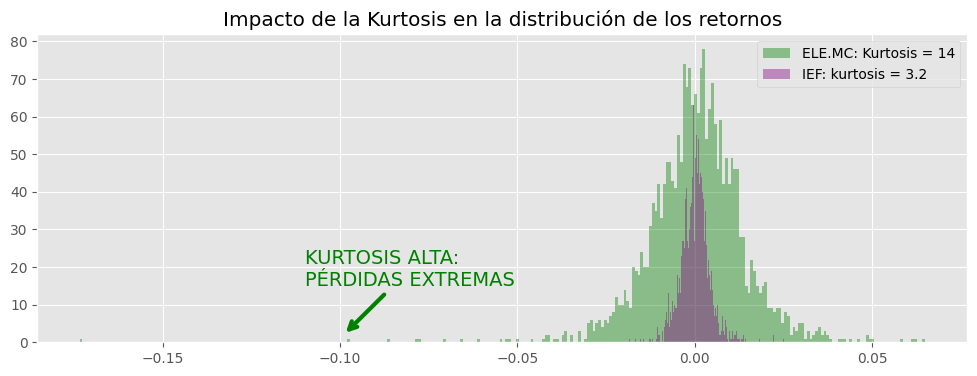

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))

plt.hist(
    ret_close_df["ELE.MC"],
    bins=300,
    color="green",
    alpha=0.4,
    label="ELE.MC: Kurtosis = 14",
)
# plt.hist(ret_close_df_corr['ORCL'], bins=300, color='green', alpha=0.4, label='ORCL')
plt.hist(
    ret_close_df["IEF"],
    bins=300,
    color="purple",
    alpha=0.4,
    label="IEF: kurtosis = 3.2",
)

# Dibuja una flecha utilizando annotate
ax.annotate(
    "KURTOSIS ALTA:\nPÉRDIDAS EXTREMAS",
    xy=(-0.099, 2),
    xytext=(-0.11, 15),
    arrowprops=dict(arrowstyle="->", linewidth=3, color="green"),
    fontsize=14,
    color="green",
)

plt.title("Impacto de la Kurtosis en la distribución de los retornos")
plt.legend()
plt.show()